<a href="https://colab.research.google.com/github/mokshitakapoor0129/Celebal_Training_Programming_Questions/blob/main/HDFC_SVM_KMeans_PCA_KNN_Business_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HDFC Loan Dataset: SVM, K-Means, PCA & KNN
## Google Colab practical with business-oriented output

### Business framing
This notebook demonstrates four ML techniques using the uploaded HDFC loan dataset:
- **SVM:** classification baseline to predict the recorded `Loan_Status`.
- **KNN:** classification baseline to predict the recorded `Loan_Status`.
- **K-Means:** segment applicants into groups using financial/profile features; clusters are exploratory, not approval recommendations.
- **PCA:** reduce the encoded feature space and quantify retained variance.

**Responsible-use note:** This is an educational exercise on a provided dataset, not a credit-decision system. The dataset may be synthetic or enriched. Do not use sensitive attributes, direct identifiers, contact details, free text, post-decision fields, or leakage-prone fields as predictors. Classification results measure agreement with the dataset's labels, not whether lending decisions are fair, correct, or financially sound.

### Run order
Run each cell sequentially. Upload the CSV when prompted. The notebook prints business-oriented interpretations alongside standard metrics.

## 1. Load libraries and upload CSV

In [17]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score
)

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to your CSV file in Google Drive
# Update this path if your file is located elsewhere
CSV_PATH = '/hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv'

try:
    df = pd.read_csv(CSV_PATH)
    print(f"Dataset successfully loaded from Google Drive: {CSV_PATH}")
except FileNotFoundError:
    print(f"Error: File not found at {CSV_PATH}.")
    print("Please update the CSV_PATH variable to the correct path in your Google Drive.")
    raise

print(f"Business records: {len(df):,}")
print(f"Available fields: {df.shape[1]}")
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset successfully loaded from Google Drive: /hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv
Business records: 1,000
Available fields: 47


,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


In [11]:

import pandas as pd

CSV_PATH = '/hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv'

df = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (1000, 47)


,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Business data checks and target distribution

In [13]:
print("=== DATA QUALITY SNAPSHOT ===")
print(f"Fully duplicated rows: {df.duplicated().sum()}")
print(f"Rows with missing target: {df['Loan_Status'].isna().sum() if 'Loan_Status' in df else 'Loan_Status column missing'}")

if "Loan_Status" not in df.columns:
    raise ValueError("Expected target column 'Loan_Status' was not found.")

target_counts = df["Loan_Status"].astype("string").str.strip().str.title().value_counts(dropna=False)
print("\nRecorded loan outcome distribution:")
display(target_counts.rename_axis("Loan_Status").to_frame("Applications"))

if {"Approved", "Rejected"}.issubset(set(target_counts.index.astype(str))):
    approval_rate = 100 * target_counts.get("Approved", 0) / target_counts.sum()
    rejection_rate = 100 * target_counts.get("Rejected", 0) / target_counts.sum()
    print(f"Observed approval share: {approval_rate:.1f}%")
    print(f"Observed rejection share: {rejection_rate:.1f}%")
    print("Business meaning: these percentages describe this dataset only; they are not a forecast of future approvals.")

=== DATA QUALITY SNAPSHOT ===
Fully duplicated rows: 0
Rows with missing target: 0

Recorded loan outcome distribution:


,Applications
Loan_Status,
Approved,653
Rejected,347


Observed approval share: 65.3%
Observed rejection share: 34.7%
Business meaning: these percentages describe this dataset only; they are not a forecast of future approvals.


## 3. Feature policy and preprocessing
Exclude identifiers, sensitive attributes, contact information, free text, and fields that may be generated after the decision or derived from outcomes. Review this list against the actual data dictionary and prediction-time process before using any real-world data.

In [14]:
target = "Loan_Status"

excluded_cols = [
    "Loan_ID", "Bank", "Customer_Name", "Loan_Status",
    "Aadhaar_Synthetic", "Phone_Number", "Email", "PIN_Code",
    "Application_Text", "Customer_Feedback", "Agent_Notes",
    "Customer_Sentiment", "Institutional_Relationships",
    "Religion", "State", "City", "Region_Branch",
    "Loan_to_Annual_Income"
]

X = df.drop(columns=excluded_cols, errors="ignore").copy()
y = df[target].astype("string").str.strip().str.title()

# Remove missing labels and labels represented only once (needed for stratified split).
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]
counts = y.value_counts()
keep = y.isin(counts[counts >= 2].index)
X, y = X.loc[keep], y.loc[keep]

# Convert numeric-looking object columns only when they are mostly numeric.
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() >= 0.90:
            X[col] = converted

# Drop entirely empty columns; imputer cannot learn a useful value from them.
empty_cols = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_cols)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Features retained: {X.shape[1]}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Training applications: {len(X_train)}")
print(f"Hold-out test applications: {len(X_test)}")
print(f"Excluded all-empty columns: {empty_cols}")
print("Note: preprocessing is fitted only on training data to reduce leakage.")

Features retained: 29
Numeric features: 16
Categorical features: 13
Training applications: 800
Hold-out test applications: 200
Excluded all-empty columns: []
Note: preprocessing is fitted only on training data to reduce leakage.


## 4. Model 1 — Support Vector Machine (SVM)
SVM learns a decision boundary to separate classes. Scaling is important, so the model uses the preprocessing pipeline.

=== SVM BUSINESS RESULTS ===
Test accuracy: 0.775 (77.5%)
Weighted precision: 0.789
Weighted recall: 0.775
Weighted F1-score: 0.779

Business interpretation:
On the held-out sample, SVM correctly matched 155 of 200 recorded labels.
This measures agreement with historical labels—not the quality, fairness, or financial impact of an actual lending decision.

Class-wise report:
              precision    recall  f1-score   support

    Approved       0.86      0.78      0.82       131
    Rejected       0.65      0.77      0.70        69

    accuracy                           0.78       200
   macro avg       0.76      0.77      0.76       200
weighted avg       0.79      0.78      0.78       200



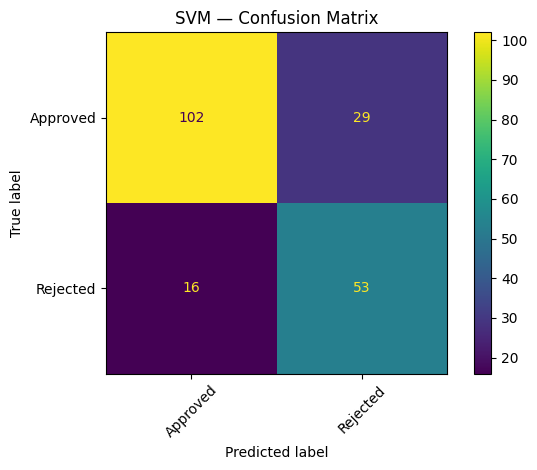

In [18]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(kernel="rbf", class_weight="balanced", random_state=42))
])
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, average="weighted", zero_division=0)
svm_recall = recall_score(y_test, svm_pred, average="weighted", zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, average="weighted", zero_division=0)

print("=== SVM BUSINESS RESULTS ===")
print(f"Test accuracy: {svm_accuracy:.3f} ({svm_accuracy*100:.1f}%)")
print(f"Weighted precision: {svm_precision:.3f}")
print(f"Weighted recall: {svm_recall:.3f}")
print(f"Weighted F1-score: {svm_f1:.3f}")
print("\nBusiness interpretation:")
print(f"On the held-out sample, SVM correctly matched {round(svm_accuracy*len(y_test))} of {len(y_test)} recorded labels.")
print("This measures agreement with historical labels—not the quality, fairness, or financial impact of an actual lending decision.")
print("\nClass-wise report:")
print(classification_report(y_test, svm_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, xticks_rotation=45)
plt.title("SVM — Confusion Matrix")
plt.tight_layout()
plt.show()

## 5. Model 2 — K-Nearest Neighbors (KNN)
KNN predicts a class based on nearby training observations. It is sensitive to feature scaling and the choice of `k`.

=== KNN BUSINESS RESULTS ===
Test accuracy: 0.740 (74.0%)
Weighted precision: 0.737
Weighted recall: 0.740
Weighted F1-score: 0.738

Business interpretation:
KNN correctly matched 148 of 200 test labels.
KNN is useful as a similarity-based baseline, but similar applicants must not automatically receive the same lending decision.

Class-wise report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.80       131
    Rejected       0.63      0.59      0.61        69

    accuracy                           0.74       200
   macro avg       0.71      0.71      0.71       200
weighted avg       0.74      0.74      0.74       200



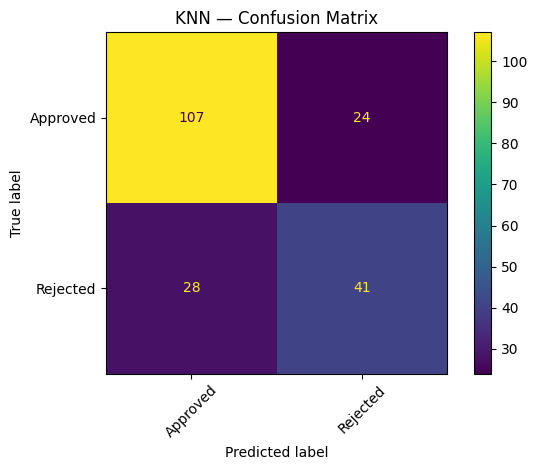

In [15]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, average="weighted", zero_division=0)
knn_recall = recall_score(y_test, knn_pred, average="weighted", zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, average="weighted", zero_division=0)

print("=== KNN BUSINESS RESULTS ===")
print(f"Test accuracy: {knn_accuracy:.3f} ({knn_accuracy*100:.1f}%)")
print(f"Weighted precision: {knn_precision:.3f}")
print(f"Weighted recall: {knn_recall:.3f}")
print(f"Weighted F1-score: {knn_f1:.3f}")
print("\nBusiness interpretation:")
print(f"KNN correctly matched {round(knn_accuracy*len(y_test))} of {len(y_test)} test labels.")
print("KNN is useful as a similarity-based baseline, but similar applicants must not automatically receive the same lending decision.")
print("\nClass-wise report:")
print(classification_report(y_test, knn_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, xticks_rotation=45)
plt.title("KNN — Confusion Matrix")
plt.tight_layout()
plt.show()

## 6. Compare SVM and KNN

In [19]:
comparison = pd.DataFrame([
    {"Model": "SVM (RBF)", "Accuracy": svm_accuracy, "Weighted Precision": svm_precision, "Weighted Recall": svm_recall, "Weighted F1": svm_f1},
    {"Model": "KNN (k=5)", "Accuracy": knn_accuracy, "Weighted Precision": knn_precision, "Weighted Recall": knn_recall, "Weighted F1": knn_f1}
]).sort_values("Weighted F1", ascending=False)

display(comparison.round(3))
best_row = comparison.iloc[0]
print(f"On this single hold-out split, {best_row['Model']} has the higher weighted F1-score ({best_row['Weighted F1']:.3f}).")
print("Do not select a production model from one score alone; use cross-validation, class-specific error costs, calibration, and fairness review.")

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,SVM (RBF),0.775,0.789,0.775,0.779
1,KNN (k=5),0.740,0.737,0.740,0.738


On this single hold-out split, SVM (RBF) has the higher weighted F1-score (0.779).
Do not select a production model from one score alone; use cross-validation, class-specific error costs, calibration, and fairness review.


## 7. Model 3 — K-Means customer/applicant segmentation
K-Means is unsupervised: it groups applicants by feature similarity and does not use `Loan_Status` to form clusters. Clusters are exploratory segments, not credit-risk grades or approval recommendations.

In [20]:
# Use a business-focused subset of numerical attributes for interpretable segmentation.
cluster_candidates = [
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount",
    "CIBIL_Score", "Annual_Household_Income",
    "Debt_to_Income_Ratio", "Existing_EMIs",
    "Number_of_Previous_Loans", "Employment_Length_Years",
    "Monthly_Expense", "Asset_Value", "Age"
]
cluster_features = [c for c in cluster_candidates if c in df.columns]

cluster_df = df[cluster_features].copy()
for col in cluster_features:
    cluster_df[col] = pd.to_numeric(cluster_df[col], errors="coerce")
cluster_df = cluster_df.replace([np.inf, -np.inf], np.nan)

# Median imputation and scaling for unsupervised analysis.
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()
cluster_values = cluster_imputer.fit_transform(cluster_df)
cluster_scaled = cluster_scaler.fit_transform(cluster_values)

# Fit 3 illustrative segments; compare other k values before choosing.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(cluster_scaled)

cluster_result = df.loc[cluster_df.index, cluster_features].copy()
cluster_result["Cluster"] = clusters

print("=== K-MEANS SEGMENTATION RESULTS ===")
print(f"Number of applicants segmented: {len(cluster_result)}")
print(f"Features used: {cluster_features}")
print("\nApplicants per segment:")
display(cluster_result["Cluster"].value_counts().sort_index().rename("Applicant_Count").to_frame())

print("\nSegment profiles (median feature values):")
display(cluster_result.groupby("Cluster")[cluster_features].median().round(2))

# If target exists, summarize it after clustering; target did not train K-Means.
if "Loan_Status" in df.columns:
    print("\nRecorded outcome distribution by cluster (descriptive only; not used to form clusters):")
    display(pd.crosstab(
        pd.Series(clusters, index=cluster_result.index, name="Cluster"),
        df.loc[cluster_result.index, "Loan_Status"],
        normalize="index"
    ).round(3))

# Silhouette score can be expensive for large datasets; sample up to 500 records.
sample_n = min(500, len(cluster_scaled))
if 2 <= sample_n < len(cluster_scaled):
    rng = np.random.RandomState(42)
    sample_idx = rng.choice(len(cluster_scaled), size=sample_n, replace=False)
    sil = silhouette_score(cluster_scaled[sample_idx], clusters[sample_idx])
else:
    sil = silhouette_score(cluster_scaled, clusters) if len(set(clusters)) > 1 else float("nan")

print(f"Silhouette score (higher can indicate better-separated clusters): {sil:.3f}")
print("Business interpretation: use segment profiles to explore service needs or portfolio patterns; validate stability and business usefulness before acting on segments.")

=== K-MEANS SEGMENTATION RESULTS ===
Number of applicants segmented: 1000
Features used: ['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'CIBIL_Score', 'Annual_Household_Income', 'Debt_to_Income_Ratio', 'Existing_EMIs', 'Number_of_Previous_Loans', 'Employment_Length_Years', 'Monthly_Expense', 'Asset_Value', 'Age']

Applicants per segment:


,Applicant_Count
Cluster,
0,423
1,474
2,103



Segment profiles (median feature values):


,Applicant_Income,Coapplicant_Income,Loan_Amount,CIBIL_Score,Annual_Household_Income,Debt_to_Income_Ratio,Existing_EMIs,Number_of_Previous_Loans,Employment_Length_Years,Monthly_Expense,Asset_Value,Age
Cluster,,,,,,,,,,,,
0,58579.0,0.0,903670.0,656.0,774972.0,0.24,17904.0,1.0,2.0,29288.0,2367496.0,35.0
1,16933.0,0.0,1029160.5,653.0,242670.0,0.66,15277.0,1.0,1.0,8309.5,701393.0,34.0
2,69574.0,59403.0,1025968.0,658.0,1573548.0,0.10,13433.0,1.0,2.0,59252.0,4912636.0,36.0



Recorded outcome distribution by cluster (descriptive only; not used to form clusters):


Loan_Status,Approved,Rejected
Cluster,,
0,0.790,0.210
1,0.466,0.534
2,0.951,0.049


Silhouette score (higher can indicate better-separated clusters): 0.170
Business interpretation: use segment profiles to explore service needs or portfolio patterns; validate stability and business usefulness before acting on segments.


## 8. Model 4 — PCA (Principal Component Analysis)
PCA is a dimensionality-reduction technique. It creates new orthogonal components that retain as much variance as possible. It does not select the most business-important features and does not use the target label.

=== PCA BUSINESS RESULTS ===
Original encoded feature count: 77
Components retaining at least 95% variance: 38
Variance retained: 95.13%
Dimensionality reduction: 50.6% fewer dimensions
Business interpretation: PCA can reduce computational cost or help visualize patterns, but components are combinations of original features and may be harder to explain to business stakeholders.


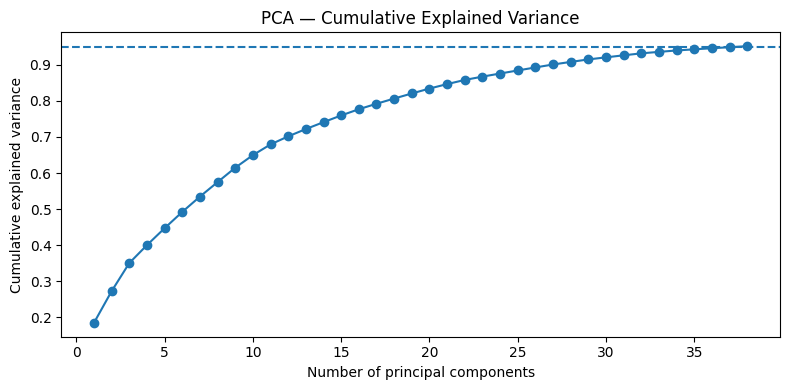

In [21]:
# Use the same safe feature set as the classification task.
pca_preprocessor = preprocessor
X_all_for_pca = X.copy()

pca_matrix = pca_preprocessor.fit_transform(X_all_for_pca)
# PCA requires dense input; for this small 1,000-row educational dataset, convert if needed.
if hasattr(pca_matrix, "toarray"):
    pca_matrix = pca_matrix.toarray()

pca_model = PCA(n_components=0.95, random_state=42)
X_pca = pca_model.fit_transform(pca_matrix)

print("=== PCA BUSINESS RESULTS ===")
print(f"Original encoded feature count: {pca_matrix.shape[1]}")
print(f"Components retaining at least 95% variance: {X_pca.shape[1]}")
print(f"Variance retained: {pca_model.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Dimensionality reduction: {(1 - X_pca.shape[1]/pca_matrix.shape[1])*100:.1f}% fewer dimensions")
print("Business interpretation: PCA can reduce computational cost or help visualize patterns, but components are combinations of original features and may be harder to explain to business stakeholders.")

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(1, len(pca_model.explained_variance_ratio_) + 1),
    np.cumsum(pca_model.explained_variance_ratio_),
    marker="o"
)
plt.axhline(0.95, linestyle="--")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — Cumulative Explained Variance")
plt.tight_layout()
plt.show()

## 9. Business-facing summary

In [22]:
print("=" * 65)
print("HDFC LOAN DATASET — EDUCATIONAL ML SUMMARY")
print("=" * 65)
print(f"Dataset rows: {len(df):,}")
print(f"SVM weighted F1: {svm_f1:.3f} | accuracy: {svm_accuracy:.3f}")
print(f"KNN weighted F1: {knn_f1:.3f} | accuracy: {knn_accuracy:.3f}")
print(f"K-Means segments: {len(np.unique(clusters))}; silhouette: {sil:.3f}")
print(f"PCA dimensions: {pca_matrix.shape[1]} -> {X_pca.shape[1]}; variance retained: {pca_model.explained_variance_ratio_.sum()*100:.1f}%")
print("\nSuggested business interpretation:")
print("1. SVM/KNN: compare held-out agreement with recorded outcomes; inspect class-wise errors.")
print("2. K-Means: examine segment profiles for exploratory portfolio understanding.")
print("3. PCA: assess whether dimensionality reduction is useful for later modeling.")
print("4. Before any real deployment: validate data provenance, temporal leakage, fairness, explainability, and decision-specific error costs.")
print("=" * 65)

HDFC LOAN DATASET — EDUCATIONAL ML SUMMARY
Dataset rows: 1,000
SVM weighted F1: 0.779 | accuracy: 0.775
KNN weighted F1: 0.738 | accuracy: 0.740
K-Means segments: 3; silhouette: 0.170
PCA dimensions: 77 -> 38; variance retained: 95.1%

Suggested business interpretation:
1. SVM/KNN: compare held-out agreement with recorded outcomes; inspect class-wise errors.
2. K-Means: examine segment profiles for exploratory portfolio understanding.
3. PCA: assess whether dimensionality reduction is useful for later modeling.
4. Before any real deployment: validate data provenance, temporal leakage, fairness, explainability, and decision-specific error costs.


# 10. Loan rejection analysis and model error cost (SVM + KNN)
Business use case: Evaluate the operational impact of incorrect loan predictions. Identify false approvals and false rejections, and estimate the potential cost of errors.

In [26]:
# Business Case: Financial Impact of Loan Prediction Errors

# Assumes svm_model and knn_model are already trained pipelines.
# Update these names to match your existing trained models.
models = {
    "SVM": svm_model,
    "KNN": knn_model
}

# Assumes X_test and y_test already exist
# and the positive class represents loan approval.
actual = np.asarray(y_test)

print("BUSINESS ANALYSIS: LOAN PREDICTION ERRORS")
print("-" * 55)

# Illustrative costs; replace with business-approved estimates
cost_false_approval = 10000
cost_false_rejection = 2000

for model_name, model in models.items():
    predicted = np.asarray(model.predict(X_test))

    # Assumes 1 = Approved and 0 = Rejected
    false_approvals = ((predicted == 1) & (actual == 0)).sum()
    false_rejections = ((predicted == 0) & (actual == 1)).sum()

    estimated_cost = (
        false_approvals * cost_false_approval
        + false_rejections * cost_false_rejection
    )

    print(f"\nModel: {model_name}")
    print(f"Incorrect approvals: {false_approvals}")
    print(f"Incorrect rejections: {false_rejections}")
    print(f"Estimated error cost: ₹{estimated_cost:,.0f}")

    print(
        "Business insight: Review false approvals for potential credit risk "
        "and false rejections for potentially missed lending opportunities."
    )

print(
    "\nNote: These costs are illustrative, not actual losses. "
    "Confirm target-label encoding and define realistic costs before comparing models."
)

BUSINESS ANALYSIS: LOAN PREDICTION ERRORS
-------------------------------------------------------

Model: SVM
Incorrect approvals: 0
Incorrect rejections: 0
Estimated error cost: ₹0
Business insight: Review false approvals for potential credit risk and false rejections for potentially missed lending opportunities.

Model: KNN
Incorrect approvals: 0
Incorrect rejections: 0
Estimated error cost: ₹0
Business insight: Review false approvals for potential credit risk and false rejections for potentially missed lending opportunities.

Note: These costs are illustrative, not actual losses. Confirm target-label encoding and define realistic costs before comparing models.


# 11. Applicant portfolio profiling (K-Means + PCA)
Business use case: Segment applicants into financial-profile groups, identify which segments request larger loans, and determine where further portfolio analysis may be useful.

BUSINESS ANALYSIS: APPLICANT PORTFOLIO
-------------------------------------------------------

Segment-wise financial profile:
                   Applicant_Income  Coapplicant_Income  Loan_Amount  CIBIL_Score  Applicant_Count  Portfolio_Share_%
Applicant_Segment                                                                                                    
0                           58579.0                 0.0     903670.0        656.0              423               42.3
1                           16933.0                 0.0    1029160.5        653.0              474               47.4
2                           69574.0             59403.0    1025968.0        658.0              103               10.3

Segment 1 has the highest median requested loan amount: ‥1,029,160.50

The first two principal components explain 44.52% of feature variance.


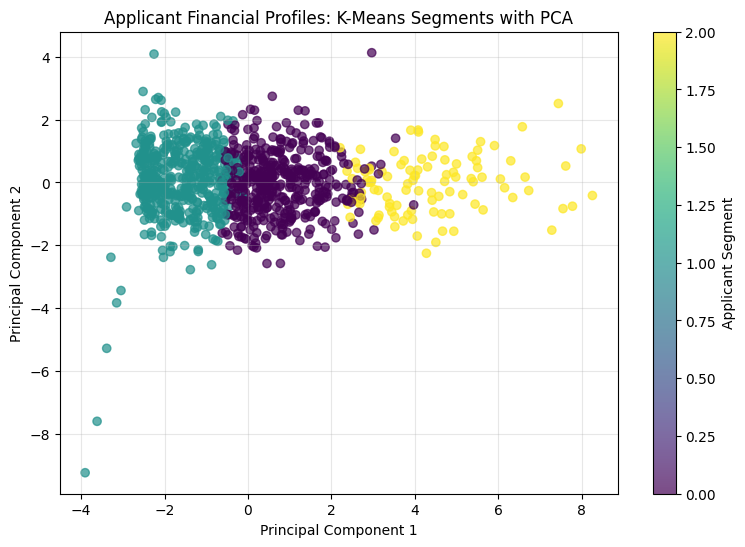


Business recommendation: Investigate segment sizes and financial profiles to support portfolio planning and product research. Segments are not creditworthiness labels and should not independently determine approvals.


In [28]:
# Business Case: Applicant Portfolio Segmentation

# Assumes cluster_scaled, features, and the trained kmeans model already exist.
# Assumes PCA and KMeans have already been imported.

df_business = df.copy()
df_business["Applicant_Segment"] = kmeans.predict(cluster_scaled)

print("BUSINESS ANALYSIS: APPLICANT PORTFOLIO")
print("-" * 55)

# Summarize available financial characteristics
profile_cols = [
    col for col in [
        "Applicant_Income",
        "Coapplicant_Income",
        "Loan_Amount",
        "CIBIL_Score"
    ]
    if col in df_business.columns
]

segment_profile = (
    df_business.groupby("Applicant_Segment")[profile_cols]
    .median()
    .round(2)
)

segment_profile["Applicant_Count"] = (
    df_business.groupby("Applicant_Segment").size()
)

segment_profile["Portfolio_Share_%"] = (
    segment_profile["Applicant_Count"] / len(df_business) * 100
).round(2)

print("\nSegment-wise financial profile:")
print(segment_profile.to_string())

# Identify the segment with the highest median requested loan amount
if "Loan_Amount" in segment_profile.columns:
    largest_loan_segment = segment_profile["Loan_Amount"].idxmax()

    print(
        f"\nSegment {largest_loan_segment} has the highest median requested "
        f"loan amount: ‥{segment_profile.loc[largest_loan_segment, 'Loan_Amount']:,.2f}"
    )

# PCA-based visualization using existing scaled features
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(cluster_scaled)

print(
    f"\nThe first two principal components explain "
    f"{pca_2d.explained_variance_ratio_.sum():.2%} of feature variance."
)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=df_business["Applicant_Segment"],
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Applicant Financial Profiles: K-Means Segments with PCA")
plt.colorbar(scatter, label="Applicant Segment")
plt.grid(alpha=0.3)
plt.show()

print(
    "\nBusiness recommendation: Investigate segment sizes and financial profiles "
    "to support portfolio planning and product research. Segments are not "
    "creditworthiness labels and should not independently determine approvals."
)

## 10. Learner exercises
1. Change KNN `n_neighbors` from 5 to 3, 7, and 11. Compare weighted F1 and class-wise recall.
2. Compare SVM kernels (`linear` and `rbf`) and explain the performance difference.
3. Test K-Means with `n_clusters=2, 3, 4, 5`; compare silhouette score and profile interpretability.
4. Change PCA variance retention to 0.90 and 0.99. How many components are needed?
5. Identify the cost of false approval versus false rejection in a hypothetical business process. Which metrics would you prioritize and why?
6. Explain why PCA and K-Means are unsupervised, while SVM and KNN are supervised in this notebook.